<img src="http://imgur.com/1ZcRyrc.png" style="float: left; margin: 20px; height: 55px">

# Time Series II: Modeling

_Author: Tim Book_

---

### Learning Objectives
By the end of this lesson, students should be able to:
- Understand the Classical decomposition of a time series
- Describe the components of the ARIMA model and their significance

In [38]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

from sklearn.model_selection import train_test_split, GridSearchCV

import statsmodels.api as sm
from itertools import product

from statsmodels.tsa.seasonal import seasonal_decompose, STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox

# Data

Today's first dataset will be the average air temperature (F) recorded at Nottingham Castle recorded monthly from 1920 to 1939

In [2]:
nottem = pd.read_csv('https://raw.githubusercontent.com/CharleyHananiaGA/DSB-Unit-03/refs/heads/main/data/nottingham.csv')
nottem.date = pd.to_datetime(nottem.date)

nottem.set_index('date', inplace=True)
nottem.head()

/tmp/ipykernel_28136/3753212424.py:2: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  nottem.date = pd.to_datetime(nottem.date)


,temp
date,
1920-01-01,40.6
1920-02-01,40.8
1920-03-01,44.4
1920-04-01,46.7
1920-05-01,54.1


In [3]:
nottem.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 240 entries, 1920-01-01 to 1939-12-01
Data columns (total 1 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   temp    240 non-null    float64
dtypes: float64(1)
memory usage: 3.8 KB


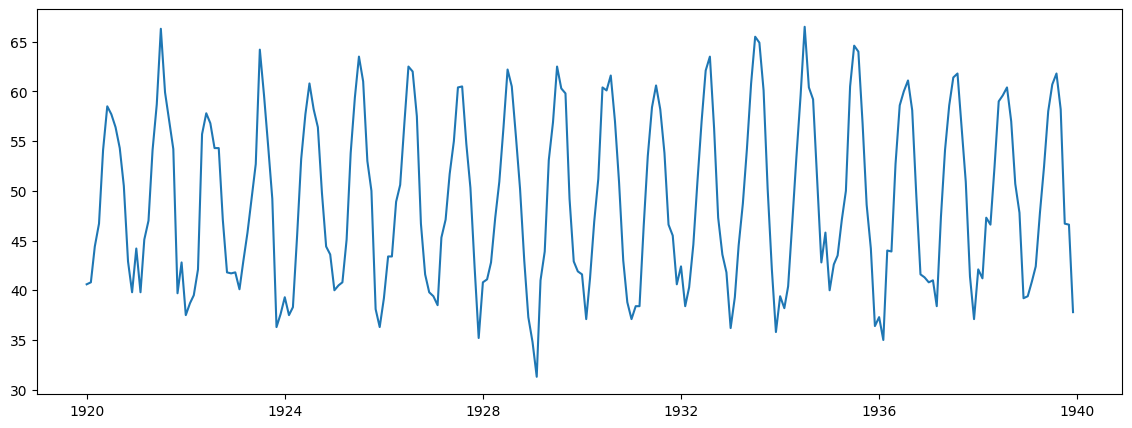

In [5]:
plt.figure(figsize=(14,5))
plt.plot(nottem);

**(THREAD):** Describe this time series. Is it stationary? Is there seasonality?

Check out the ACF plot, PACF plot, and the `statsmodels` decomposition below. Does this validate your opinions?

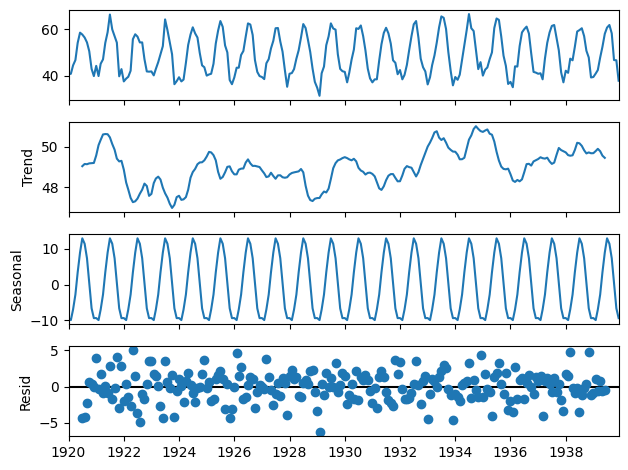

In [6]:
# Decomposition
decomp = seasonal_decompose(nottem)
decomp.plot();

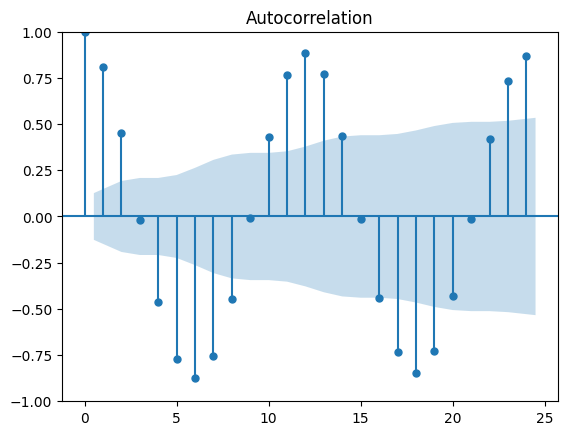

In [8]:
# ACF
# We see a strong autocorrelation (self-correlation) at 1, 6, 12, 18, 24
plot_acf(nottem);

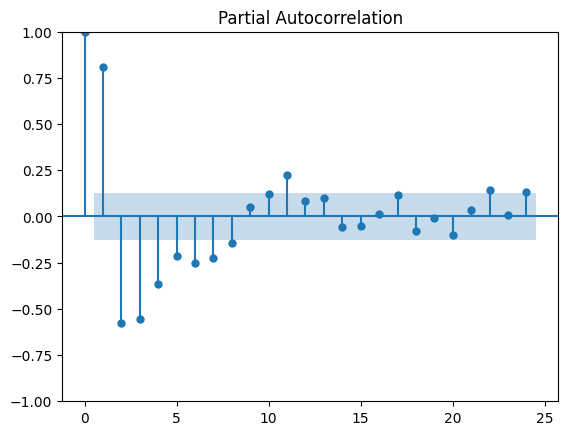

In [9]:
# PACF
plot_pacf(nottem);

# Model Prep

In [10]:
# Do a train-test split holding out only 10% of our data unshuffled (why?)
nottem['month'] = nottem.index.month
y_train, y_test = train_test_split(nottem, test_size=0.1, shuffle=False, random_state=123)

y_train.shape, y_test.shape

((216, 2), (24, 2))

# Create components
- $m_t$ : We'll assume no trend here and just let $\hat m_t = \bar y$
- $s_t$ : Since we have monthly data we'll just let $\hat s_t$ be the mean temperature per month with the trend removed.

In [14]:
mt = y_train.temp.mean()
print(f'Mean temperature for the training set is: {mt:.2f}');

Mean temperature for the training set is: 48.95


In [16]:
y_train.groupby('month', as_index=False).temp.mean()
st = y_train.groupby('month', as_index=False).temp.mean()
st['seasonal'] = st.temp - mt

print(f"\nSeasonal component for each month:")
st.round(2)


Seasonal component for each month:


,month,temp,seasonal
0,1,39.58,-9.37
1,2,38.98,-9.97
2,3,41.90,-7.05
3,4,46.19,-2.76
4,5,52.58,3.63
5,6,57.99,9.04
6,7,62.09,13.14
7,8,60.46,11.50
8,9,56.36,7.40
9,10,49.58,0.63


# Predictions
This might not _feel_ like a model, but we actually have enough to make predictions now. Let's merge the seasonal components back onto the testing data and add the trend back on. Those are our predictions!

In [17]:
y_test_pred = y_test.merge(st[['month', 'seasonal']], how='left')

y_test_pred['y_pred'] = mt + y_test_pred['seasonal']



In [19]:
y_test_pred.index = y_test.index
y_test_pred

,temp,month,seasonal,y_pred
date,,,,
1938-01-01,42.1,1,-9.373611,39.577778
1938-02-01,41.2,2,-9.968056,38.983333
1938-03-01,47.3,3,-7.051389,41.900000
1938-04-01,46.6,4,-2.762500,46.188889
1938-05-01,52.4,5,3.626389,52.577778
1938-06-01,59.0,6,9.037500,57.988889
1938-07-01,59.6,7,13.143056,62.094444
1938-08-01,60.4,8,11.504167,60.455556
1938-09-01,57.0,9,7.404167,56.355556


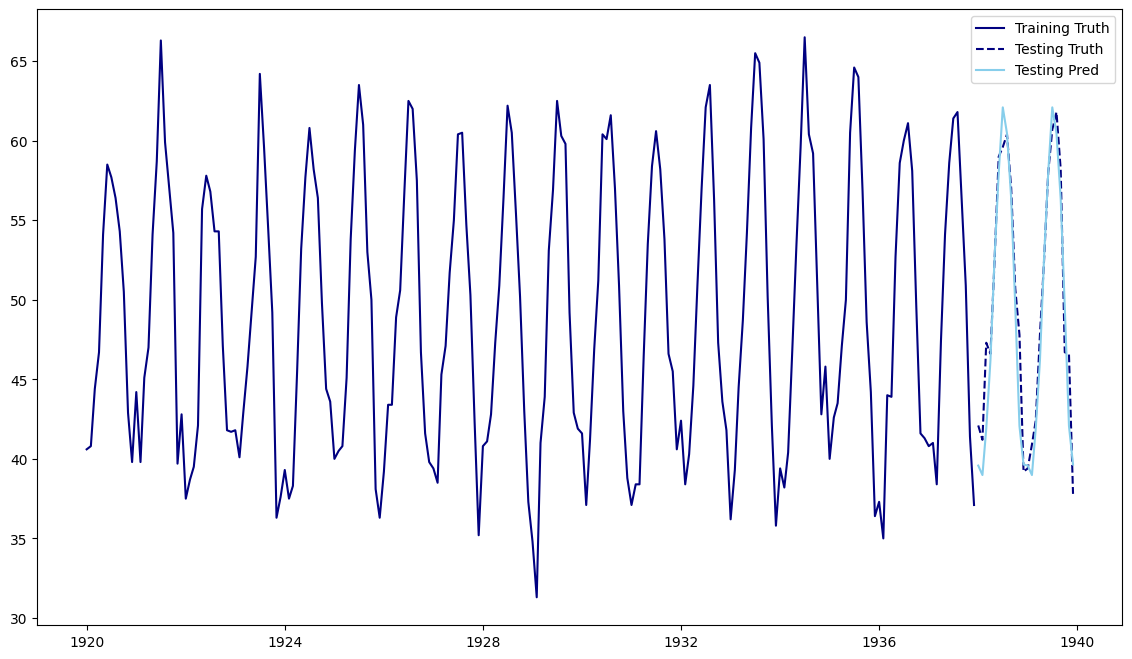

In [20]:
# Pretty good!
plt.figure(figsize=(14, 8))
plt.plot(y_train.temp, c='navy', label='Training Truth')
plt.plot(y_test_pred.temp, c='navy', linestyle='--', label='Testing Truth')
plt.plot(y_test_pred.y_pred, c='skyblue', label='Testing Pred')

plt.legend();

# ARIMA with Airline Data
Our second dataset is monthly airline data from Box and Jenkins (1976).

In [22]:

# air = pd.read_csv('https://raw.githubusercontent.com/CharleyHananiaGA/DSB-Unit-03/refs/heads/main/data/airline-passengers.csv', parse_dates=['Month'], index_col='Month', date_format='%Y-%m')
air = pd.read_csv('https://raw.githubusercontent.com/CharleyHananiaGA/DSB-Unit-03/refs/heads/main/data/airline-passengers.csv')
air.Month = pd.to_datetime(air.Month)
air.set_index('Month', inplace=True)

air.head()


,Passengers
Month,
1949-01-01,112
1949-02-01,118
1949-03-01,132
1949-04-01,129
1949-05-01,121


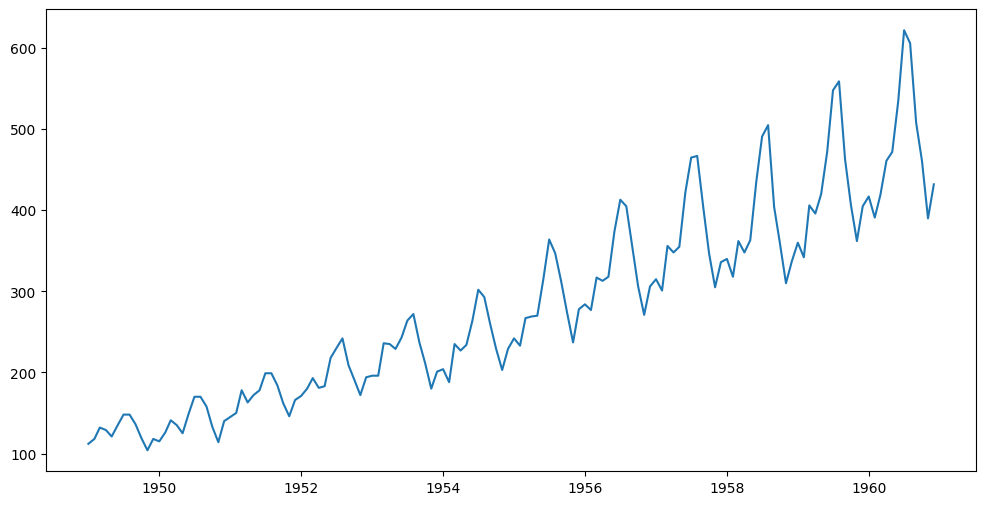

In [23]:
plt.figure(figsize=(12, 6))
plt.plot(air);

**(THREAD):** Let's set aside the last 24 rows (two years) as testing data _without using the_ `train_test_split()` function!

In [24]:
h = 24
y_train = air.iloc[:-h]
y_test = air.iloc[-h:]

In [26]:
y_train.shape, y_test.shape

((120, 1), (24, 1))

## Stationarity with the ADF Test

Let's do some EDA to see how many diffs it takes to achieve stationarity. We'll also do an **Augmented Dickey-Fuller test** to be "official" about it.

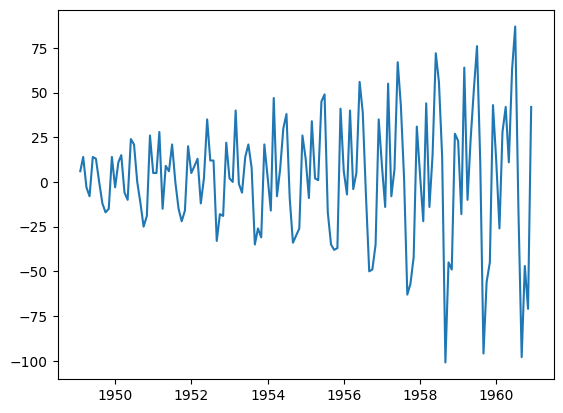

In [27]:
# Once is probably fine
plt.plot(air.diff());

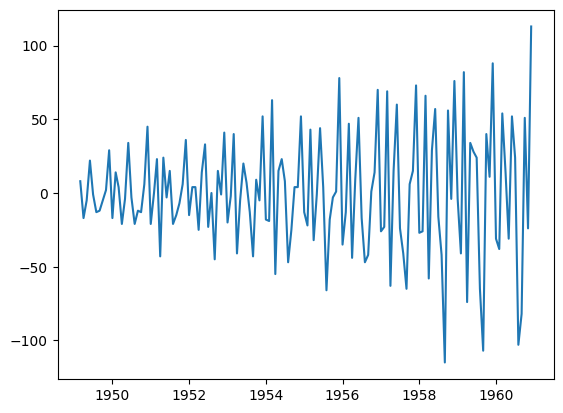

In [28]:
# Twice doesn't change much
plt.plot(air.diff().diff());

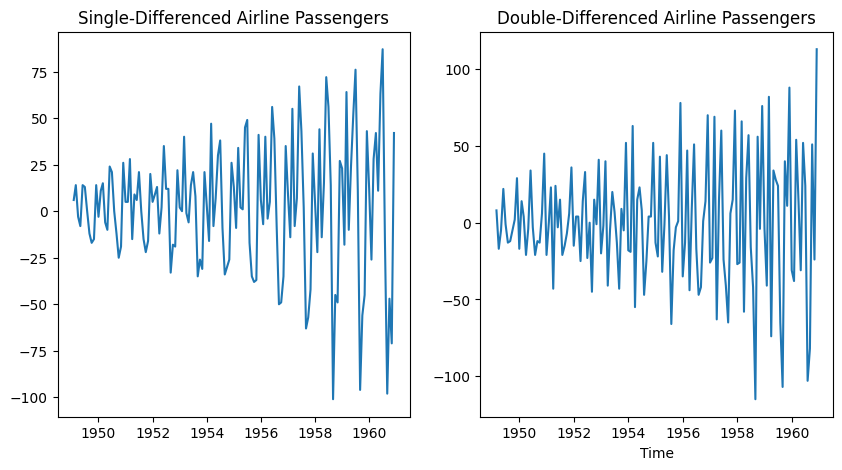

In [29]:
# We described previously that in a real machine learning pipeline, we don't actually need a distinct test for every scenario because the remedies to fix non-stationarity are very straightforward:
#1. If it fails the ADF (Has a Trend): Apply First-Order Differencing (df.diff()). This subtracts yesterday's value from today's value, flattening out the trend line.
#2. If it fails the KPSS (Has Seasonality): Apply Seasonal Differencing (df.diff(periods=12)). This subtracts last year's value from this year's value to strip out cyclical waves.
#3. If it has Changing Variance (Megaphone shape): Apply a Log Transform (np.log(df)) or a Box-Cox transformation. This compresses the large swings down to a uniform scale.

air_diff  = air.diff()
air_ddiff = air.diff().diff()

plt.figure(figsize=(10,5))
plt.subplot(1,2,1)

plt.plot(air_diff)
plt.title('Single-Differenced Airline Passengers')

plt.subplot(1,2,2)
plt.plot(air_ddiff)
plt.title('Double-Differenced Airline Passengers')

plt.xlabel('Time')
plt.show()

## The **Augmented** Dickey Fuller test
The technicalities are outside our scope, but you can read more about it [here](https://en.wikipedia.org/wiki/Augmented_Dickey%E2%80%93Fuller_test).

In short, we're testing:

$$
H_0: \text{time series not stationary} \\
H_A: \text{time series stationary}
$$

The result is a **p-value**

**Decision Rules for the p-value**

* p-value ≤ significance level (e.g., < 0.05):
	- **Decision:** *Reject* the null hypothesis (H₀).
	- **Conclusion:** The data is stationary. It has a stable mean, variance, and autocovariance over time, making it safe for models like ARIMA.
* p-value > significance level (e.g., ≥ 0.05):
	- **Decision:** *Fail to reject* the null hypothesis (H₀).
	- **Conclusion:** The data is non-stationary (or has a unit root/trend). We need to apply transformations like differencing before further modeling.

In [32]:
adf_diff1, pval_diff1, *_ = adfuller(air.diff().dropna(), result_object=True)
adf_diff2, pval_diff2, *_ = adfuller(air.diff().diff().dropna(), result_object=True)

print(f"diff'd once  p-value = {pval_diff1:.40f}\ndiff'd twice p-value = {pval_diff2:.40f}\n")
# Looks like we may have to diff twice to be stationary!

if (pval_diff1 <= 0.05):
    print(f"ADF Test: the Single-Differenced Airline Passengers data is Stationary!")
else:
    print(f"ADF Test: the Single-Differenced Airline Passengers data is non-Stationary!")


if (pval_diff2 <= 0.05):
    print(f"ADF Test: the Double-Differenced Airline Passengers data is Stationary!")
else:
    print(f"ADF Test: the Double-Differenced Airline Passengers data is non-Stationary!")


diff'd once  p-value = 0.0542132902838247804355731318537436891347
diff'd twice p-value = 0.0000000000000000000000000000273289185001

ADF Test: the Single-Differenced Airline Passengers data is non-Stationary!
ADF Test: the Double-Differenced Airline Passengers data is Stationary!


## First Attempt: ARIMA(1, 2, 1)

Let's use `statsmodels` to fit an ARIMA(1, 2, 1) model.

In [34]:
model = ARIMA(y_train, order=(1, 2, 1)).fit()


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)


In [36]:
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             Passengers   No. Observations:                  120
Model:                 ARIMA(1, 2, 1)   Log Likelihood                -560.986
Date:                Mon, 26 Oct 2026   AIC                           1127.973
Time:                        12:34:52   BIC                           1136.285
Sample:                    01-01-1949   HQIC                          1131.348
                         - 12-01-1958                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1          0.2939      0.110      2.665      0.008       0.078       0.510
ma.L1         -0.9998      7.840     -0.128      0.899     -16.366      14.366
sigma2       761.3284   5998.922      0.127      0.899    -1.1e+04    1.25e+04
===================================================================================
Ljung-Box (L1) (Q):                   0.38   Jarque-Bera (JB):                 5.62
Prob(Q):                              0.54   Prob(JB):                         0.06
Heteroskedasticity (H):               7.13   Skew:                            -0.07
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.06
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

## Evaluation

You might notice a lack of $R^2$! The preferred evaluation metric is the [Akaike Information Criterion (AIC)](https://en.wikipedia.org/wiki/Akaike_information_criterion). It won't make sense at first glance - but it's an error metric where lower is better, and it's based off the specific loss function of the ARIMA model.

**TL;DR:** We'll use AIC as our model evaluation of choice. Lower is better!

In [37]:
model.aic

np.float64(1127.9725713067216)

## "Grid Search"

Since we're using `statsmodels`, we can actually use `GridSearchCV`, but that's ok! We can make our own loop.

In [ ]:
from itertools import product

In [59]:
%%time

p_array = np.arange(13)
d_array = np.arange(3)
d_val = 2
q_array = np.arange(13)

results = []

for p, q in product(p_array, q_array):
    model = ARIMA(y_train, order=(p, d_val, q)).fit()
    results.append((p, q, model.aic))


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_date

CPU times: user 7min 55s, sys: 593 ms, total: 7min 56s
Wall time: 5min 32s


/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


In [60]:
df_res = pd.DataFrame(results, columns=['p', 'q', 'aic'])
df_res.sort_values('aic').head(10)


,p,q,aic
146,11,3,921.371745
147,11,4,922.962877
148,11,5,924.893203
144,11,1,925.525455
156,12,0,926.034058
149,11,6,926.719885
145,11,2,927.183376
160,12,4,927.431393
158,12,2,927.541598
159,12,3,927.744083


In [61]:
# Best model summary
best_p, best_q = df_res.sort_values('aic', ascending=True).iloc[0][['p', 'q']]

In [63]:
# model = ARIMA(y_train, order=(11,2,3)).fit()
model = ARIMA(y_train, order=(best_p, d_val, best_q)).fit()
model.summary()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/base/tsa_model.py:480: ValueWarning: No frequency information was provided, so inferred frequency MS will be used.
  self._init_dates(dates, freq)
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-stationary starting autoregressive parameters found. Using zeros as starting parameters.
  start_params = self.start_params
/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:679: EstimationWarning: Non-invertible starting MA parameters found. Using zeros 

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:             Passengers   No. Observations:                  120
Model:                ARIMA(11, 2, 3)   Log Likelihood                -445.686
Date:                Mon, 26 Oct 2026   AIC                            921.372
Time:                        13:36:21   BIC                            962.932
Sample:                    01-01-1949   HQIC                           938.246
                         - 12-01-1958                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
ar.L1         -0.8514      0.112     -7.588      0.000      -1.071      -0.632
ar.L2         -0.9823      0.058    -16.952      0.000      -1.096      -0.869
ar.L3         -0.8439      0.096     -8.833      0.000      -1.031      -0.657
ar.L4         -0.9403      0.057    -16.437      0.000      -1.052      -0.828
ar.L5         -0.8229      0.094     -8.748      0.000      -1.007      -0.639
ar.L6         -0.9276      0.056    -16.678      0.000      -1.037      -0.819
ar.L7         -0.8328      0.093     -8.908      0.000      -1.016      -0.650
ar.L8         -0.9452      0.058    -16.260      0.000      -1.059      -0.831
ar.L9         -0.8651      0.088     -9.875      0.000      -1.037      -0.693
ar.L10        -0.9637      0.039    -24.774      0.000      -1.040      -0.887
ar.L11        -0.8308      0.095     -8.733      0.000      -1.017      -0.644
ma.L1         -0.3595      0.169     -2.125      0.034      -0.691      -0.028
ma.L2          0.2006      0.185      1.082      0.279      -0.163       0.564
ma.L3         -0.3300      0.169     -1.955      0.051      -0.661       0.001
sigma2        96.9405     16.502      5.875      0.000      64.598     129.283
===================================================================================
Ljung-Box (L1) (Q):                   0.00   Jarque-Bera (JB):                 9.17
Prob(Q):                              0.95   Prob(JB):                         0.01
Heteroskedasticity (H):               2.75   Skew:                            -0.08
Prob(H) (two-sided):                  0.00   Kurtosis:                         4.36
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

# Predictions and Evaluation

In [64]:
y_test_pred = model.predict(start=y_test.index[0], end=y_test.index[-1])

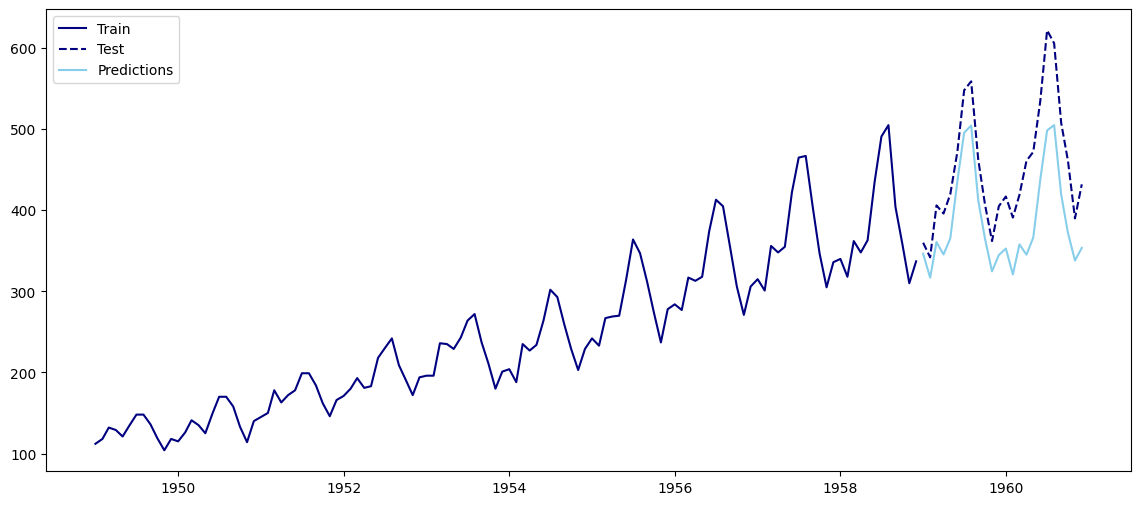

In [65]:
plt.figure(figsize=(14, 6))
plt.plot(y_train, c='navy', label='Train')
plt.plot(y_test, c='navy', linestyle='--', label='Test')
plt.plot(y_test_pred, c='skyblue', label='Predictions')
plt.legend();

There appears to be some series underestimation - this is normal for a model like this that appears to have rising variance over time!

# Conclusions and Takeaways
- You can use simple heuristics rather than ML models to make forecasts on certain scenarios
- The ARIMA model is the base form of models for modeling time series
- There are many variants and additions to the ARIMA model!
- TS modeling works best when the past predicts future. Weather, sales, and deaths - yes! The stock market - no!